In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from tqdm import tqdm
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

import warnings
warnings.filterwarnings('ignore')


plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [2]:
def load_and_analyze_dataset(n):
    """this loads the dataset and provides basic analysis of the provided data"""
    X = np.load(f'Datasets/kryptonite-{n}-X.npy')
    y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)

    print(f"\n{'='*50}")
    print(f"Dataset Kryptonite-{n}")
    print(f"Shape: {X.shape}")
    print(f"Class distribution: {np.bincount(y)}")
    print(f"Class balance: {y.mean():.3f}")
    
    return X, y
    


Dataset Kryptonite-10
Shape: (20000, 10)
Class distribution: [10016  9984]
Class balance: 0.499

Dataset Kryptonite-12
Shape: (24000, 12)
Class distribution: [11912 12088]
Class balance: 0.504

Dataset Kryptonite-14
Shape: (28000, 14)
Class distribution: [14095 13905]
Class balance: 0.497

Dataset Kryptonite-16
Shape: (32000, 16)
Class distribution: [15897 16103]
Class balance: 0.503

Dataset Kryptonite-18
Shape: (36000, 18)
Class distribution: [18003 17997]
Class balance: 0.500

Dataset Kryptonite-20
Shape: (40000, 20)
Class distribution: [20206 19794]
Class balance: 0.495


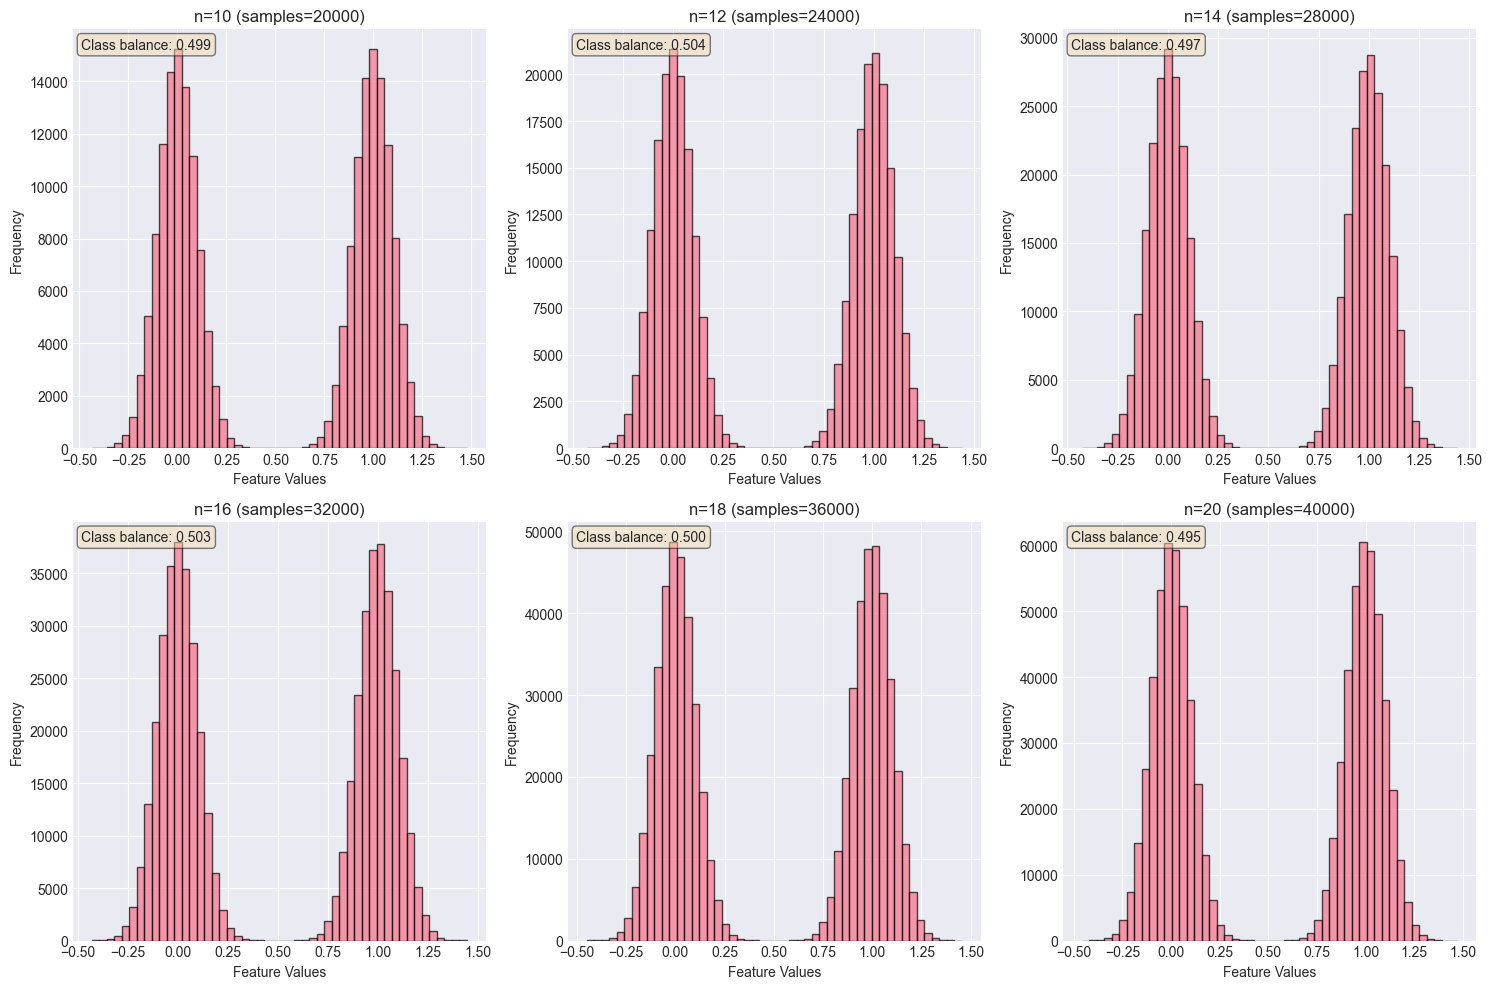

In [3]:
def create_dataset_overview_figure():
    """Figure 1: Dataset characteristics across different n values"""
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    #fig.suptitle('Figure 1: Kryptonite Dataset Characteristics', fontsize=16)
    
    n_values = [10, 12, 14, 16, 18, 20]
    
    for idx, n in enumerate(n_values):
        ax = axes[idx // 3, idx % 3]
        X, y = load_and_analyze_dataset(n)
        
        # Feature distribution
        ax.hist(X.flatten(), bins=50, alpha=0.7, edgecolor='black')
        ax.set_title(f'n={n} (samples={len(X)})')
        ax.set_xlabel('Feature Values')
        ax.set_ylabel('Frequency')
        
        # Add class balance as text
        ax.text(0.02, 0.98, f'Class balance: {y.mean():.3f}', 
                transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.savefig('figures/dataset_overview.png', dpi=150, bbox_inches='tight')
    plt.show()
    
create_dataset_overview_figure()

In [4]:
class ModelExperiment:
    def __init__(self, n_value):
        self.n = n_value
        self.target = {10: 0.94, 12: 0.93, 14: 0.92, 
                      16: 0.91, 18: 0.80, 20: 0.75}[n_value]
        self.X, self.y = self.load_data()
        self.results = {}

    def load_data(self):
        X = np.load(f'Datasets/kryptonite-{self.n}-X.npy')
        y = np.load(f'Datasets/kryptonite-{self.n}-y.npy').astype(int)
        return X, y

    def split_data(self):
        """ as per the paper 60/20/20 split"""
        X_train, X_temp, y_train, y_temp = train_test_split(
            self.X, self.y, test_size=0.4, random_state=42, stratify=self.y
        )
        X_val, X_test, y_val, y_test = train_test_split(
            X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
        )
        return X_train, X_val, X_test, y_train, y_val, y_test

    def run_experiments(self):
        """ this is to run experiments with 5-fold cross validation on training data, select on validation"""
        X_train, X_val, X_test, y_train, y_val, y_test = self.split_data()

        models = {
            'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=20, random_state=42),
            'GradientBoosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
            'ExtraTrees': ExtraTreesClassifier(n_estimators=300, random_state=42),
            'NeuralNetwork': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
        }

        for name, model in models.items():
            # 5-FOLD CROSS-VALIDATION ON TRAINING DATA
            cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
            cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
            
            # Train on full training data and evaluate on validation
            if name == 'NeuralNetwork':
                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_val_scaled = scaler.transform(X_val)
                X_test_scaled = scaler.transform(X_test)
                
                model.fit(X_train_scaled, y_train)
                val_acc = model.score(X_val_scaled, y_val)
                test_acc = model.score(X_test_scaled, y_test)  # ONLY FOR FINAL REPORTING
            else:
                scaler = None
                model.fit(X_train, y_train)
                val_acc = model.score(X_val, y_val)
                test_acc = model.score(X_test, y_test)  # ONLY FOR FINAL REPORTING

            self.results[name] = {
                'model': model,
                'scaler': scaler,
                'cv_mean': cv_scores.mean(),
                'cv_std': cv_scores.std(),
                'val_acc': val_acc,  # this will be used for model selection
                'test_acc': test_acc, 
                'final_test_acc': None,
                'cv_scores': cv_scores
            }

        return self.results


In [ ]:
all_results = {}
significance_results = {}

for n in tqdm([10, 12, 14, 16, 18, 20], desc=f"Running First Series of Kryptonite-2.0 Experiments"):
    exp = ModelExperiment(n)
    results = exp.run_experiments()
    all_results[n] = results
    
    print(f"\n{'='*50}")
    print(f"Kryptonite-{n} Results (Target: {exp.target:.2f})")
    print(f"{'='*50}")
    
    for model_name, res in results.items():
        # Statistical test: is cv_mean significantly > target?
        cv_scores = res['cv_scores']
        t_stat, p_value = stats.ttest_1samp(cv_scores, exp.target)
        significant = p_value < 0.05 and res['cv_mean'] > exp.target
        
        significance_results[f"{n}_{model_name}"] = {
            't_stat': float(t_stat),
            'p_value': float(p_value),
            'significant': bool(significant)
        }
        
        print(f"  {model_name:15s}: CV={res['cv_mean']:.4f}±{res['cv_std']:.4f} | "
              f"Val={res['val_acc']:.4f} | Test={res['test_acc']:.4f} | "
              f"p={p_value:.3f} {'✓' if significant else '✗'}")

# Save significance results for paper

with open('results/significance_tests.json', 'w') as f:
    json.dump(significance_results, f, indent=2)

Running First Series of Kryptonite-2.0 Experiments:  17%|███▏               | 1/6 [01:42<08:30, 102.20s/it]


Kryptonite-10 Results (Target: 0.94)
  RandomForest   : CV=0.5085±0.0094 | Val=0.4933 | Test=0.5155 | p=0.000 ✗
  GradientBoosting: CV=0.5008±0.0086 | Val=0.4998 | Test=0.5110 | p=0.000 ✗
  ExtraTrees     : CV=0.8078±0.0141 | Val=0.8393 | Test=0.8420 | p=0.000 ✗
  NeuralNetwork  : CV=0.9513±0.0049 | Val=0.9410 | Test=0.9413 | p=0.010 ✓


In [ ]:
def create_performance_comparison_figure(all_results):
    """Figure 2: Model performance across different n values with error bars"""
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    n_values = [10, 12, 14, 16, 18, 20]
    targets = {10: 0.94, 12: 0.93, 14: 0.92, 16: 0.91, 18: 0.80, 20: 0.75}

    for idx, n in enumerate(n_values):
        ax = axes[idx // 3, idx % 3]

        # extract results - USE VALIDATION ACCURACY FOR SELECTION
        model_names = list(all_results[n].keys())
        val_accs = [all_results[n][m]['val_acc'] for m in model_names]
        cv_means = [all_results[n][m]['cv_mean'] for m in model_names]
        cv_stds = [all_results[n][m]['cv_std'] for m in model_names]

        # create bar plot with ERROR BARS from CV
        bars = ax.bar(range(len(model_names)), cv_means, yerr=cv_stds, 
                      capsize=5, alpha=0.7, color='skyblue')

        # color bars based on VALIDATION performance vs target
        for i, (bar, val_acc) in enumerate(zip(bars, val_accs)):
            if val_acc >= targets[n]:
                bar.set_color('green')
            else:
                bar.set_color('red')
        #note: the bar is based on the val_acc whereas the bar height is based on the cv_means
        
        
        ax.axhline(y=targets[n], color='black', linestyle='--', 
                   label=f'Target: {targets[n]}')

        # Formatting
        ax.set_title(f'Kryptonite-{n}', fontsize=12, fontweight='bold')
        ax.set_xticks(range(len(model_names)))
        ax.set_xticklabels(model_names, rotation=45, ha='right')
        ax.set_ylabel('CV Accuracy ± Std', fontsize=10)
        ax.set_ylim([0.4, 1.0])
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)

        # Add value labels (CV mean ± std)
        for i, (bar, mean, std) in enumerate(zip(bars, cv_means, cv_stds)):
            ax.text(bar.get_x() + bar.get_width()/2, mean + std + 0.02,
                   f'{mean:.3f}', ha='center', va='bottom', fontsize=8)

    # plt.suptitle('Figure 2: Cross-Validated Performance vs Targets', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('figures/performance_comparison_cv.png', dpi=300, bbox_inches='tight')
    plt.show()

create_performance_comparison_figure(all_results)

In [ ]:
def plot_learning_curves():
    """Figure 3: Learning curves for best performing models"""
    
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    # fig.suptitle('Figure 3: Learning Curves for Best Models', fontsize=16)
    
    for idx, n in enumerate([10, 12, 14, 16, 18, 20]):
        ax = axes[idx // 3, idx % 3]
        
        # Get best model for this n
        X, y = load_and_analyze_dataset(n)
        
        # Fix: train_test_split returns only 4 values
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.4, random_state=42, stratify=y
        )
        
        # Use Neural Network since it's performing best
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        
        model = MLPClassifier(
            hidden_layer_sizes=(100, 50), 
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42
        )
        
        train_sizes, train_scores, val_scores = learning_curve(
            model, X_train_scaled, y_train, cv=5, 
            train_sizes=np.linspace(0.1, 1.0, 10),
            scoring='accuracy', n_jobs=-1
        )
        
        ax.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', label='Training score')
        ax.plot(train_sizes, np.mean(val_scores, axis=1), 's-', label='Cross-validation score')
        ax.fill_between(train_sizes, 
                        np.mean(train_scores, axis=1) - np.std(train_scores, axis=1),
                        np.mean(train_scores, axis=1) + np.std(train_scores, axis=1), 
                        alpha=0.1)
        ax.fill_between(train_sizes,
                        np.mean(val_scores, axis=1) - np.std(val_scores, axis=1),
                        np.mean(val_scores, axis=1) + np.std(val_scores, axis=1),
                        alpha=0.1)
        
        # Add target accuracy line
        target = {10: 0.94, 12: 0.93, 14: 0.92, 16: 0.91, 18: 0.80, 20: 0.75}[n]
        ax.axhline(y=target, color='red', linestyle='--', alpha=0.5, label=f'Target: {target}')
        
        ax.set_title(f'n={n}')
        ax.set_xlabel('Training Set Size')
        ax.set_ylabel('Accuracy')
        ax.legend(loc='lower right')
        ax.grid(True, alpha=0.3)
        ax.set_ylim([0.4, 1.0])
    
    plt.tight_layout()
    plt.savefig('figures/learning_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_learning_curves()

In [ ]:
os.makedirs('hiddenlabels', exist_ok=True)
def generate_hidden_predictions():
    """Generate predictions for hidden test sets using VALIDATION-selected models"""

    for n in [10, 12, 14, 16, 18, 20]:
        print(f"\n{'='*50}")
        print(f"\nGenerating predictions for n={n}")

        # Load hidden test set
        X_hidden = np.load(f'Datasets/hidden-kryptonite-{n}-X.npy')
        print(f"  Hidden test samples: {len(X_hidden)}")

        # Get best model based on VALIDATION ACCURACY (NOT TEST)
        exp = ModelExperiment(n)  # Creates fresh splits
        results = exp.run_experiments()
        
        best_model_name = max(results.keys(), 
                             key=lambda k: results[k]['val_acc'])  # FIX: use val_acc
        best_model_data = results[best_model_name]

        print(f"  Using best model: {best_model_name}")
        print(f"  Validation accuracy: {best_model_data['val_acc']:.4f}")
        print(f"  CV accuracy: {best_model_data['cv_mean']:.4f}±{best_model_data['cv_std']:.4f}")

        # Make predictions
        model = best_model_data['model']
        if best_model_data['scaler'] is not None:
            X_hidden_scaled = best_model_data['scaler'].transform(X_hidden)
            y_pred = model.predict(X_hidden_scaled)
        else:
            y_pred = model.predict(X_hidden)

        # Validate predictions
        assert len(y_pred) == 10000, f"Expected 10000 predictions, got {len(y_pred)}"
        assert y_pred.dtype in [np.int32, np.int64], f"Predictions must be integers"
        assert set(np.unique(y_pred)) <= {0, 1}, f"Predictions must be binary"

        # Save predictions
        output_path = f'hiddenlabels/y_predicted_{n}.npy'
        np.save(output_path, y_pred.astype(int))
        print(f"  Saved to {output_path}")
        print(f"  Class distribution: {np.bincount(y_pred)}")

generate_hidden_predictions()

In [ ]:
def optimize_and_generate_predictions():
    """
    Nested optimization: Use validation for architecture selection,
    then train final model on full (train+val) before predicting hidden set.
    """
    from sklearn.model_selection import KFold
    
    # Results storage
    final_results = {}
    architecture_history = {}
    
    # Define architecture search space
    search_spaces = {
        10: [(128, 64), (256, 128, 64)],
        12: [(128, 64), (256, 128, 64)],
        14: [(256, 128, 64), (512, 256, 128)],
        16: [(512, 256, 128), (1024, 512, 256, 128)],
        18: [(512, 256, 128)],
        20: [(256, 128), (512, 256, 128),(512, 512, 256, 128)]
    }
    
    for n in tqdm([10, 12, 14, 16, 18, 20], desc=f"Running Second Series of Kryptonite-2.0 Experiments to validation for architecture selection"):
        print(f"\n{'='*60}")
        print(f"OPTIMIZING ARCHITECTURE FOR n={n}")
        print(f"{'='*60}")
        
        # Load full dataset
        X = np.load(f'Datasets/kryptonite-{n}-X.npy')
        y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)
        X_hidden = np.load(f'Datasets/hidden-kryptonite-{n}-X.npy')
        
        # Split: 60% train, 20% val, 20% test (test stays locked)
        X_train_full, X_temp, y_train_full, y_temp = train_test_split(
            X, y, test_size=0.4, random_state=42, stratify=y
        )
        X_val, X_test, y_val, y_test = train_test_split(
            X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
        )
        
        best_val_score = 0
        best_arch = None

        # TRAINING CONFIGURATION
        max_iter = 5000 if n >= 18 else 2000  # More training for hard cases
        batch_size = 64 if n >= 18 else 32    # Larger batches for stability
        
        # ARCHITECTURE SEARCH ON VALIDATION SET
        for arch in search_spaces[n]:
            model = MLPClassifier(
                hidden_layer_sizes=arch,
                activation='relu',
                solver='adam',
                alpha=0.001,
                batch_size=batch_size,
                max_iter=max_iter,
                early_stopping=True,
                n_iter_no_change=100,
                validation_fraction=0.2,
                random_state=42
            )
            
            # Scale data
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train_full)
            X_val_scaled = scaler.transform(X_val)
            
            model.fit(X_train_scaled, y_train_full)
            val_score = model.score(X_val_scaled, y_val)
            
            print(f"  Arch {arch}: Val Accuracy = {val_score:.4f}")
            
            if val_score > best_val_score:
                best_val_score = val_score
                best_arch = arch
        
        print(f"  → Selected Architecture: {best_arch} (Val: {best_val_score:.4f})")
        architecture_history[n] = {'arch': best_arch, 'val_score': best_val_score}
        
        # FINAL MODEL: Train on (train+val) and evaluate on test ONCE
        X_final_train = np.vstack([X_train_full, X_val])
        y_final_train = np.hstack([y_train_full, y_val])
        
        final_scaler = StandardScaler()
        X_final_train_scaled = final_scaler.fit_transform(X_final_train)
        X_test_scaled = final_scaler.transform(X_test)
        
        final_model = MLPClassifier(
            hidden_layer_sizes=best_arch,
            activation='relu',
            solver='adam',
            alpha=0.0001,
            batch_size=32,
            max_iter=2000,
            early_stopping=False,  # Use all data
            random_state=42
        )
        
        final_model.fit(X_final_train_scaled, y_final_train)
        test_score = final_model.score(X_test_scaled, y_test)
        
        print(f"  → Final Test Accuracy: {test_score:.4f}")
        
        # Generate predictions for HIDDEN SET
        X_hidden_scaled = final_scaler.transform(X_hidden)
        y_pred = final_model.predict(X_hidden_scaled)
        
        # Save predictions
        np.save(f'hiddenlabels/y_predicted_{n}.npy', y_pred.astype(int))
        
        final_results[n] = {
            'architecture': best_arch,
            'val_score': best_val_score,
            'test_score': test_score,
            'predictions': y_pred
        }
    
    # Save optimization history
    with open('results/architecture_optimization.json', 'w') as f:
        json.dump(architecture_history, f, indent=2)
    
    return final_results

# Run optimization and generate final predictions
final_results = optimize_and_generate_predictions()

# Summary
print("\n" + "="*60)
print("FINAL OPTIMIZATION SUMMARY")
print("="*60)
for n, res in final_results.items():
    print(f"n={n:2d}: Arch={res['architecture']}, Val={res['val_score']:.4f}, Test={res['test_score']:.4f}")

In [ ]:
def polynomial_comparison_cv():
    """Compare methods with proper cross-validation to avoid leakage"""
    
    results = {
        'n': [], 'poly_deg2_cv': [], 'poly_deg2_std': [],
        'neural_net_cv': [], 'neural_net_std': []
    }

    for n in [10, 12, 14, 16, 18, 20]:
        X = np.load(f'Datasets/kryptonite-{n}-X.npy')
        y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)
        
        results['n'].append(n)
        
        # Polynomial degree 2 with CV
        poly2 = PolynomialFeatures(degree=2)
        X_poly2 = poly2.fit_transform(X)
        
        lr2 = LogisticRegression(max_iter=1000, solver='lbfgs')
        cv_scores_lr2 = cross_val_score(lr2, X_poly2, y, cv=5, scoring='accuracy')
        results['poly_deg2_cv'].append(cv_scores_lr2.mean())
        results['poly_deg2_std'].append(cv_scores_lr2.std())
        
        # Neural Network with CV
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        nn = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=42)
        cv_scores_nn = cross_val_score(nn, X_scaled, y, cv=5, scoring='accuracy')
        results['neural_net_cv'].append(cv_scores_nn.mean())
        results['neural_net_std'].append(cv_scores_nn.std())
        
        print(f"n={n:2d}: Poly2={cv_scores_lr2.mean():.3f}±{cv_scores_lr2.std():.3f} | "
              f"NN={cv_scores_nn.mean():.3f}±{cv_scores_nn.std():.3f}")

    return pd.DataFrame(results)

poly_results_cv = polynomial_comparison_cv()

In [ ]:
def create_all_figures_from_results(final_results, poly_results_cv):
    """Generate figures from ACTUAL experimental results"""
    
    # Figure 1: Architecture Search Results
    fig, ax = plt.subplots(figsize=(12, 6))
    
    n_values = [10, 12, 14, 16, 18, 20]
    architectures = [final_results[n]['architecture'] for n in n_values]
    val_scores = [final_results[n]['val_score'] for n in n_values]
    
    # Plot validation scores during architecture search
    bars = ax.bar(range(len(n_values)), val_scores, color='steelblue', alpha=0.7)
    
    # Add target lines
    targets = [0.94, 0.93, 0.92, 0.91, 0.80, 0.75]
    ax.plot(range(len(n_values)), targets, 'ro--', label='Target Accuracy')
    
    ax.set_xlabel('Dataset Dimension (n)', fontsize=12)
    ax.set_ylabel('Validation Accuracy', fontsize=12)
    ax.set_title('Architecture Search: Validation Performance', fontsize=14, fontweight='bold')
    ax.set_xticks(range(len(n_values)))
    ax.set_xticklabels([f'n={n}\n{arch}' for n, arch in zip(n_values, architectures)], 
                       rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.4, 1.0])
    
    # Add value labels
    for bar, score in zip(bars, val_scores):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{score:.3f}', ha='center', va='bottom', fontsize=9)
    
    plt.tight_layout()
    plt.savefig('figures/architecture_search.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Figure 2: Polynomial vs NN (CV results)
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Use real CV results from poly_results_cv
    nn_scores = poly_results_cv['neural_net_cv']
    poly_scores = poly_results_cv['poly_deg2_cv']
    
    x = np.arange(len(n_values))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, nn_scores, width, label='Neural Network', 
                   color='green', alpha=0.8)
    bars2 = ax.bar(x + width/2, poly_scores, width, label='Polynomial (deg 2)', 
                   color='orange', alpha=0.8)
    
    ax.plot(x, targets, 'k--', label='Target', linewidth=2)
    
    ax.set_xlabel('Dataset (n)', fontsize=12)
    ax.set_ylabel('Cross-Validation Accuracy', fontsize=12)
    ax.set_title('Neural Networks vs Polynomial Regression', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(n_values)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.4, 1.0])
    
    plt.tight_layout()
    plt.savefig('figures/nn_vs_poly_cv.png', dpi=300, bbox_inches='tight')
    plt.show()

# Run this AFTER you have final_results and poly_results_cv
create_all_figures_from_results(final_results, poly_results_cv)